# Can graph features predict electoral tilt?
**Target.** `tilt` = (own two-party share this election - last election) - (own party's national two-party share this year - last year), for incumbents who ran. Positive = did better than the national swing implied. Built by `build_targets.py`.

**Setup.** For each Congress we build features from that Congress's member--bill Yea graph, then predict the tilt of the election that follows it.
Train on the 115th and 116th (2018, 2020), **test on the 118th (2024)**. The 117th (2022, heavy redistricting) is set aside.

**Caveat.** The graph only has Yea edges, so a Nay and an absence look the same. A Nay and an absence look identical, so we avoid features that need Nays: "disloyalty" counts Yeas cast against the own party, which Yea edges identify exactly.

In [1]:
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

TRAIN, TEST = [115, 116], 118
targets = pd.read_csv("data/elections/targets.csv")
print(targets[targets.congress.isin(TRAIN + [TEST])].groupby("congress").tilt.agg(["count", "mean", "std"]).round(3))

          count   mean    std
congress                     
115         281 -0.021  0.037
116         327  0.003  0.032
118         320 -0.001  0.026


## 1. Features from the graph
One row per member per Congress.

In [2]:
def graph_features(c, k=15):
    mem = pd.read_csv(f"data/{c}/voteview/H{c}_members.csv")
    mem = mem[(mem.chamber == "House") & mem.bioguide_id.notna()].drop_duplicates("bioguide_id").set_index("bioguide_id")
    party = mem.party_code.map({100: "D", 200: "R"}).fillna("O")
    bills = pd.read_csv(f"data/{c}/bills.csv").drop_duplicates("bill_number").set_index("bill_number")
    edges = pd.read_csv(f"data/{c}/edges.csv").drop_duplicates(["member", "bill"])
    B = (pd.crosstab(edges.member, edges.bill).reindex(index=mem.index, columns=bills.index, fill_value=0) > 0).astype(float)
    Bv, n = B.values, B.values.sum(1)
    D, R = (party == "D").values, (party == "R").values
    pv = party.to_numpy(dtype=object)
    same = (pv[:, None] == pv[None, :]) & ~np.eye(len(pv), dtype=bool)
    other = ((pv[:, None] == "D") & R[None, :]) | ((pv[:, None] == "R") & D[None, :])

    f = pd.DataFrame(index=B.index)
    # -- bipartite-side features: what kind of bills does the member back?
    sh_D, sh_R = Bv[D].mean(0), Bv[R].mean(0)          # per-bill share of each party voting Yea
    own = np.where(D[:, None], sh_D[None, :], np.where(R[:, None], sh_R[None, :], np.nan))
    oth = np.where(D[:, None], sh_R[None, :], np.where(R[:, None], sh_D[None, :], np.nan))
    f["n_yeas"] = np.log1p(n)
    f["yea_failed_share"] = (Bv @ (bills.outcome.values == "failed")) / np.maximum(n, 1)
    f["mean_bill_yeas"] = (Bv @ bills.yea_count.values) / np.maximum(n, 1)     # how mainstream the backed bills are
    f["own_support"] = np.nansum(Bv * own, 1) / np.maximum(n, 1)
    f["other_support"] = np.nansum(Bv * oth, 1) / np.maximum(n, 1)
    f["offparty_share"] = (Bv * (own < 0.5)).sum(1) / np.maximum(n, 1)         # Yeas on bills their own party mostly opposed
    # Disloyalty: Yeas cast AGAINST the own party (bill backed by under 50% / under 30% of own party). Only needs Yea edges, so absences do not matter.
    f["cross_yeas"] = np.log1p((Bv * (own < 0.5)).sum(1))
    f["cross_yeas_strict"] = np.log1p((Bv * (own < 0.3)).sum(1))

    # -- latent position: top-2 SVD of the centered member x bill matrix (an ideal-point proxy)
    U, s, _ = np.linalg.svd(Bv - Bv.mean(0), full_matrices=False)
    emb = U[:, :2] * s[:2]
    if emb[R, 0].mean() < emb[D, 0].mean(): emb[:, 0] *= -1
    f["ideal1"], f["ideal2"] = emb[:, 0], emb[:, 1]
    cen = {"D": emb[D].mean(0), "R": emb[R].mean(0)}
    d_own = np.linalg.norm(emb - np.where(D[:, None], cen["D"], cen["R"]), axis=1)
    d_oth = np.linalg.norm(emb - np.where(D[:, None], cen["R"], cen["D"]), axis=1)
    f["dist_own_centroid"], f["dist_other_centroid"] = d_own, d_oth
    f["rel_dist_own"] = d_own / (d_own + d_oth)                                # 0.5 = midway between the parties

    # -- member-projection (co-Yea cosine similarity): centrality notions
    Z = Bv / np.maximum(np.linalg.norm(Bv, axis=1, keepdims=True), 1e-9)
    S = Z @ Z.T; np.fill_diagonal(S, 0)
    f["sim_all"] = S.sum(1) / (len(S) - 1)                                       # weighted degree
    f["sim_same_party"] = (S * same).sum(1) / np.maximum(same.sum(1), 1)
    f["sim_other_party"] = (S * other).sum(1) / np.maximum(other.sum(1), 1)
    f["eigcent"] = np.abs(np.linalg.eigh(S)[1][:, -1])
    f["pagerank"] = pd.Series(nx.pagerank(nx.from_numpy_array(S), weight="weight")).values
    nbrs = np.argsort(-S, axis=1)[:, :k]                                          # k nearest co-voters
    K = nx.Graph(); K.add_nodes_from(range(len(S))); K.add_edges_from((i, j) for i in range(len(S)) for j in nbrs[i])
    f["knn_betweenness"] = pd.Series(nx.betweenness_centrality(K)).values        # bridging between voting blocs
    f["knn_cross_share"] = np.array([(pv[nbrs[i]] != pv[i]).mean() for i in range(len(S))])

    # -- sponsorship
    sp = pd.read_csv(f"data/{c}/sponsors.csv").bioguide.value_counts()
    f["n_sponsored"] = np.log1p(sp.reindex(B.index).fillna(0).values)
    return f.assign(congress=c, bioguide=B.index.values)

feats = pd.concat([graph_features(c) for c in TRAIN + [TEST]], ignore_index=True)
FEATS = [c for c in feats.columns if c not in ("congress", "bioguide")]
print(len(FEATS), "features;", feats.shape[0], "member-congress rows")

21 features; 1349 member-congress rows


## 2. Join to the target
Features are z-scored within each Congress (target-free), so scales are comparable across years. `tilt_c` is the tilt with its (congress, party) mean removed: whether a member beat their *own party's* average that year, which strips out party-wide shocks like the 2018 Republican slide.

In [3]:
d = targets.merge(feats, on=["congress", "bioguide"])
d = d[d.tilt.notna() & d.party.isin(["D", "R"])].copy()
d["tilt_c"] = d.tilt - d.groupby(["congress", "party"]).tilt.transform("mean")
d["is_R"] = (d.party == "R").astype(float)
d["prev_share"] = d.prev_two_party_share
z = lambda x: (x - x.mean()) / x.std()
d[FEATS + ["prev_share"]] = d.groupby("congress")[FEATS + ["prev_share"]].transform(z)
d[FEATS] = d[FEATS].fillna(0)
print(d.groupby(["congress", "party"]).agg(n=("tilt", "size"), tilt_mean=("tilt", "mean"), tilt_sd=("tilt", "std")).round(3))

                  n  tilt_mean  tilt_sd
congress party                         
115      D      117     -0.012    0.030
         R      164     -0.027    0.040
116      D      177     -0.010    0.028
         R      150      0.019    0.029
118      D      158      0.001    0.031
         R      162     -0.003    0.021


## 3. Univariate look: does each feature correlate with `tilt_c`, and is the sign stable across years?

In [4]:
rows = []
for f_ in FEATS + ["prev_share"]:
    r = {"feature": f_}
    for c in TRAIN + [TEST]:
        s = d[d.congress == c]; r[c] = spearmanr(s[f_], s.tilt_c)[0]
    rows.append(r)
uni = pd.DataFrame(rows).set_index("feature")
uni["same_sign"] = (np.sign(uni[115]) == np.sign(uni[116])) & (np.sign(uni[116]) == np.sign(uni[118]))
uni["mean_abs"] = uni[[115, 116, 118]].abs().mean(1)
print("Spearman correlation with tilt_c, by congress")
uni.sort_values("mean_abs", ascending=False).round(3)

Spearman correlation with tilt_c, by congress


C:\Users\1980h\AppData\Local\Temp\ipykernel_33632\3517051257.py:9: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  uni["mean_abs"] = uni[[115, 116, 118]].abs().mean(1)


,115,116,118,same_sign,mean_abs
feature,,,,,
prev_share,-0.103,-0.198,-0.289,True,0.197
pagerank,0.102,0.192,0.137,True,0.144
sim_all,0.103,0.191,0.136,True,0.143
eigcent,0.100,0.187,0.136,True,0.141
sim_other_party,0.088,0.206,0.121,True,0.139
sim_same_party,0.095,0.156,0.134,True,0.128
ideal2,-0.070,-0.134,0.173,False,0.126
n_yeas,0.082,0.178,0.076,True,0.112
ideal1,0.069,-0.167,0.004,False,0.080


## 4. Models
Ridge regression (penalty chosen by leave-one-Congress-out on 115/116), evaluated on 118. `oos R2` is relative to predicting the *training* mean, so 0 = no better than a constant and it can go negative.

In [5]:
def ridge(X, y, lam):
    mu, ym = X.mean(0), y.mean()
    beta = np.linalg.solve((X - mu).T @ (X - mu) + lam * np.eye(X.shape[1]), (X - mu).T @ (y - ym))
    return (lambda Xn: ym + (Xn - mu) @ beta), beta

def run(cols, target):
    tr, te = d[d.congress.isin(TRAIN)], d[d.congress == TEST]
    cv = {}
    for lam in [1, 10, 100, 1000, 10000]:
        cv[lam] = sum(((b[target].values - ridge(a[cols].values, a[target].values, lam)[0](b[cols].values)) ** 2).sum()
                      for a, b in [(tr[tr.congress != h], tr[tr.congress == h]) for h in TRAIN])
    lam = min(cv, key=cv.get)
    pred, beta = ridge(tr[cols].values, tr[target].values, lam)
    p, y = pred(te[cols].values), te[target].values
    sse0 = ((y - tr[target].mean()) ** 2).sum()
    return {"lambda": lam, "oos R2": 1 - ((y - p) ** 2).sum() / sse0, "test corr": pearsonr(p, y)[0],
            "test RMSE": np.sqrt(((y - p) ** 2).mean()), "const RMSE": np.sqrt(sse0 / len(y))}, p, beta

sets = {"party only": ["is_R"], "party + prev share": ["is_R", "prev_share"], "graph only": FEATS,
        "graph + party": FEATS + ["is_R"], "graph + party + prev share": FEATS + ["is_R", "prev_share"]}
res, store = [], {}
for target in ["tilt", "tilt_c"]:
    for name, cols in sets.items():
        m, p, beta = run(cols, target); store[(target, name)] = (p, beta, cols)
        res.append({"target": target, "features": name, **m})
pd.DataFrame(res).set_index(["target", "features"]).round(3)

lambda  oos R2  test corr  test RMSE  const RMSE
target features                                                                    
tilt   party only                   10000  -0.000     -0.084      0.027       0.027
       party + prev share           10000   0.007      0.272      0.027       0.027
       graph only                     100  -0.039      0.026      0.028       0.027
       graph + party                  100  -0.042      0.024      0.028       0.027
       graph + party + prev share     100   0.021      0.185      0.027       0.027
tilt_c party only                       1   0.000      0.000      0.026       0.026
       party + prev share              10   0.077      0.286      0.025       0.026
       graph only                    1000   0.004      0.067      0.026       0.026
       graph + party                 1000   0.004      0.067      0.026       0.026
       graph + party + prev share     100   0.069      0.280      0.025       0.026

## 5. What is the model using, and how does it look on the test year?

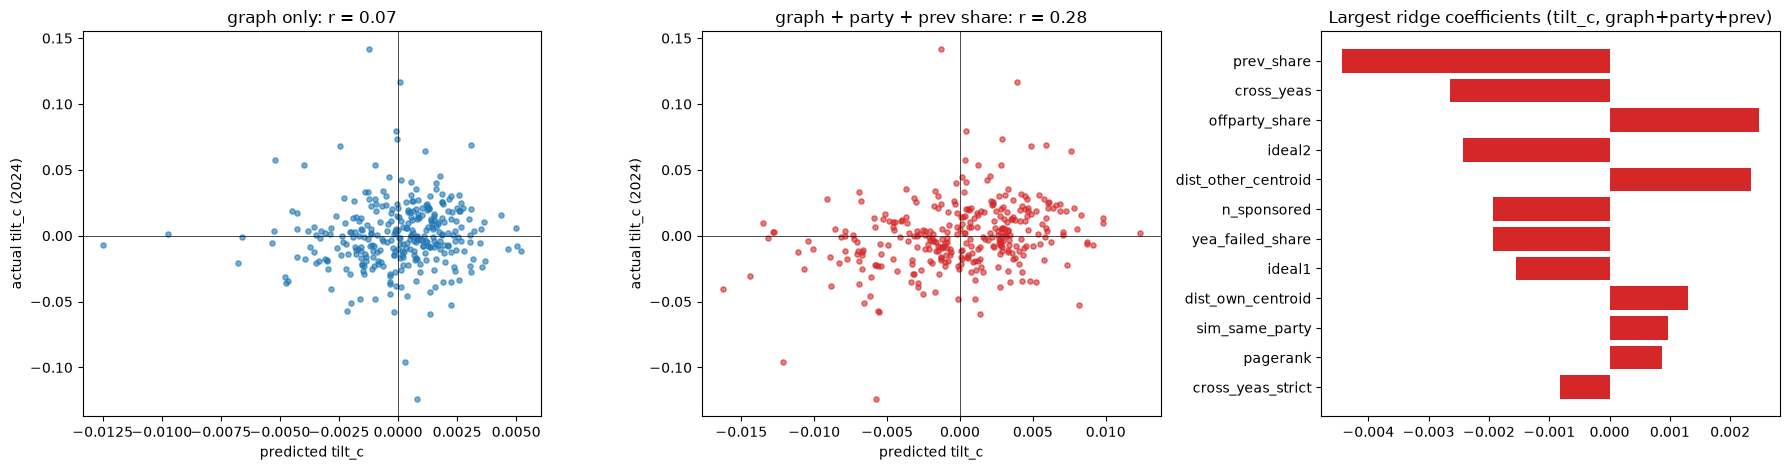

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
te = d[d.congress == TEST]
for a, (name, color) in zip(ax[:2], [("graph only", "#1f77b4"), ("graph + party + prev share", "#d62728")]):
    p = store[("tilt_c", name)][0]
    a.scatter(p, te.tilt_c, s=14, alpha=0.6, color=color); a.axhline(0, c="k", lw=0.5); a.axvline(0, c="k", lw=0.5)
    a.set(xlabel="predicted tilt_c", ylabel="actual tilt_c (2024)", title=f"{name}: r = {pearsonr(p, te.tilt_c)[0]:.2f}")
_, beta, cols = store[("tilt_c", "graph + party + prev share")]
order = np.argsort(np.abs(beta))[-12:]
ax[2].barh([cols[i] for i in order], beta[order], color="#d62728"); ax[2].set(title="Largest ridge coefficients (tilt_c, graph+party+prev)")
plt.tight_layout(); plt.show()

## 6. Nonlinear models
Same split. Shallow, heavily regularized trees, since there are only ~600 training rows.

In [7]:
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor

tr, te = d[d.congress.isin(TRAIN)], d[d.congress == TEST]
models = {"random forest": lambda: RandomForestRegressor(300, min_samples_leaf=15, max_features=0.4, random_state=236, n_jobs=-1),
          "xgboost": lambda: XGBRegressor(n_estimators=200, max_depth=2, learning_rate=0.03, subsample=0.7,
                                          colsample_bytree=0.6, min_child_weight=10, reg_lambda=5, random_state=236)}
res2, imp = [], {}
for target in ["tilt", "tilt_c"]:
    for sname in ["graph only", "graph + party + prev share"]:
        cols = sets[sname]
        for mname, mk in models.items():
            m = mk().fit(tr[cols], tr[target]); p, y = m.predict(te[cols]), te[target].values
            sse0 = ((y - tr[target].mean()) ** 2).sum()
            res2.append({"target": target, "features": sname, "model": mname, "oos R2": 1 - ((y - p) ** 2).sum() / sse0,
                         "test corr": pearsonr(p, y)[0], "test RMSE": np.sqrt(((y - p) ** 2).mean())})
            imp[(target, sname, mname)] = pd.Series(m.feature_importances_, index=cols)
print(pd.DataFrame(res2).set_index(["target", "features", "model"]).round(3))
print("\nTop importances (xgboost, graph + party + prev share, tilt_c):")
print(imp[("tilt_c", "graph + party + prev share", "xgboost")].sort_values(ascending=False).head(8).round(3))

                                                 oos R2  test corr  test RMSE
target features                   model                                      
tilt   graph only                 random forest  -0.310     -0.011      0.031
                                  xgboost        -0.424     -0.059      0.032
       graph + party + prev share random forest  -0.299      0.082      0.031
                                  xgboost        -0.272      0.068      0.031
tilt_c graph only                 random forest  -0.063     -0.042      0.027
                                  xgboost        -0.126     -0.053      0.028
       graph + party + prev share random forest   0.001      0.129      0.026
                                  xgboost        -0.056      0.084      0.027

Top importances (xgboost, graph + party + prev share, tilt_c):
prev_share             0.074
ideal2                 0.058
cross_yeas             0.056
offparty_share         0.050
sim_other_party        0.049
dist_other_

## What we notice (first pass)
1. **Graph features alone do not predict 2024 tilt.** Out-of-sample R2 is about 0 for ridge (graph only: 0.004 on `tilt_c`) and negative for random forest / xgboost, which overfit ~600 training rows.
2. **The one real signal is `prev_share`, with a negative sign.** Members who did well last time do worse than the uniform-swing baseline (rho = -0.10, -0.20, -0.29 in 2018, 2020, 2024): regression to the mean. The tilt definition assumes last-time share carries over one-for-one, and it does not. Party + prev share gets test corr about 0.28 and R2 about 0.08 on `tilt_c`; adding graph features does not improve it (0.069).
3. **Disloyalty (crossover Yeas) does not predict tilt.** `cross_yeas` (Yeas on bills <50% of own party backed) has rho = -0.12, 0.00, +0.05 across the three years: the sign is not stable. The strict version (<30%) is about 0 everywhere. This replaced the earlier absence-contaminated "loyalty" feature.
4. **Centrality has a consistent but weak positive link.** `pagerank`, `sim_all`, `eigcent`, `sim_other_party` correlate about +0.1 to +0.2 with `tilt_c` in all three years: members central in the co-Yea network outperform. They are highly collinear, and the effect is small. Next step: check whether it survives controlling for `prev_share` and district lean.
5. **Ideal-point features flip sign across years**, so no consistent "extremists underperform" story.
6. **Most of the target is noise.** Test-year tilt SD is about 0.026 and the best model barely beats a constant.

**Ideas next:** pool more Congresses (so there are more than ~600 rows); add district partisanship (presidential vote); handle 117's redistricting instead of dropping it; use real Nay/absent votes from Voteview; replace the uniform-swing baseline with the fitted regression residual.